<a href="https://colab.research.google.com/github/MCD-PUC-Chile/MDS3020/blob/main/Clase2_Datos_Sinteticos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Clase 2 — **Generación de datos sintéticos**

**Objetivo:** Comprender qué son los datos sintéticos, por qué son relevantes en la ciencia de datos moderna y cómo generarlos de forma práctica con Python.



## 0) Preparación del entorno (Colab/Jupyter)
Ejecuta esta celda para instalar y cargar librerías. *En Colab puede tardar unos minutos.*


In [1]:
!pip install -q faker pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 8.2 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
from datetime import datetime, date
from math import floor
import matplotlib.pyplot as plt

print("Librerías cargadas. Versión pandas:", pd.__version__)


Librerías cargadas. Versión pandas: 2.2.3



## 1) Motivación — ¿Por qué datos sintéticos?
- **Escasez de datos**: datasets pequeños, fenómenos raros (fraude, fallas).
- **Privacidad**: no podemos compartir datos sensibles (salud, finanzas).
- **Costo/tiempo**: obtener datos reales puede ser caro o lento.
- **Docencia & pruebas**: necesitamos *datos realistas* para practicar pipelines.

**Idea clave:** Los datos sintéticos **no reemplazan** a los reales; **los complementan** y permiten experimentar con libertad y responsabilidad.



## 2) Conceptos clave
- **Definición:** datos generados artificialmente que imitan propiedades de los reales.
- **Dos enfoques comunes:**
  - *Simulación/reglas* (p. ej., [`Faker`](https://faker.readthedocs.io)): crear campos plausibles según formatos/heurísticas.
  - *Modelos generativos* (p. ej., `ydata-synthetic`, `SDV`): aprenden la **distribución** de un dataset real y generan muestras nuevas.
- **Usos típicos:** ampliar muestras, balancear clases, proteger privacidad, probar dashboards/pipelines.
- **Cuándo no usarlos:** cuando requieres exactitud clínica/forense o ya dispones de datos completos y autorizados.



## 3) Demo A — Generación con `Faker` (rápido y flexible)
**Objetivo:** crear un dataset ficticio de compras para practicar EDA, limpieza y visualización.


In [3]:

from faker import Faker
fake = Faker('es_ES')

def generar_compras(n=1000, seed=42):
    Faker.seed(seed)
    rng = np.random.default_rng(seed)
    datos = []
    for _ in range(n):
        edad = rng.integers(18, 71) #regla establecida por el usuario
        monto = float(np.round(rng.uniform(5.0, 500.0), 2)) #regla 2
        datos.append({
            "id_cliente": fake.uuid4(), #user id con convencion standard de bbdd
            "nombre": fake.name(), #de un catalogo pre-establecido de faker
            "edad": int(edad), #de la regla establecida
            "ciudad": fake.city(), # de Faker
            "fecha_compra": fake.date_between(start_date='-6M', end_date='today'), #utilidad de Faker
            "monto": monto, # de la regla #2
            "categoria": rng.choice(["supermercado","tecnología","hogar","ropa","salud"], p=[0.35,0.2,0.15,0.2,0.1])
        })
    return pd.DataFrame(datos)

df = generar_compras(n=800, seed=2025) # muy importante documentar la semilla
df.head()


,id_cliente,nombre,edad,ciudad,fecha_compra,monto,categoria
0,d66887a3-a556-4782-952b-f8818ec8d8bc,Carmela Ángel Abad,41,Jaén,2026-08-02,194.09,ropa
1,19025fcd-669f-49ff-a1f8-416310d7543a,Benigno Galán Peña,70,La Rioja,2026-04-29,419.44,salud
2,111b3025-829d-4eed-8dc3-78970722756e,Rogelio Fajardo,38,Teruel,2026-05-31,162.14,salud
3,a381d5df-c823-4411-b0b7-cd55c93c3fbd,Águeda Seguí Pablo,22,Pontevedra,2026-05-10,339.56,supermercado
4,3e52de23-1f39-4f9a-b54b-1e0232b6e075,Alejandra Azahar Cerdán Pedro,18,Palencia,2026-07-13,118.96,supermercado


In [9]:
df

,id_cliente,nombre,edad,ciudad,fecha_compra,monto,categoria
0,d66887a3-a556-4782-952b-f8818ec8d8bc,Carmela Ángel Abad,41,Jaén,2026-08-02,194.09,ropa
1,19025fcd-669f-49ff-a1f8-416310d7543a,Benigno Galán Peña,70,La Rioja,2026-04-29,419.44,salud
2,111b3025-829d-4eed-8dc3-78970722756e,Rogelio Fajardo,38,Teruel,2026-05-31,162.14,salud
3,a381d5df-c823-4411-b0b7-cd55c93c3fbd,Águeda Seguí Pablo,22,Pontevedra,2026-05-10,339.56,supermercado
4,3e52de23-1f39-4f9a-b54b-1e0232b6e075,Alejandra Azahar Cerdán Pedro,18,Palencia,2026-07-13,118.96,supermercado
...,...,...,...,...,...,...,...
795,145b7f87-b53e-44d6-9f41-763a1ec9732c,Encarna de Moll,52,Castellón,2026-05-07,206.95,ropa
796,53441253-f79c-4105-845b-0015b8bfa4ff,Alberto Ruy Doménech Pulido,69,Cantabria,2026-05-04,487.03,tecnología
797,7c0afce1-972e-41ca-9ea4-98c5430d212d,Amado Zaragoza Marti,45,Almería,2026-09-24,72.08,ropa
798,ef176c02-f37a-4e80-b669-0cd16e7d4b76,Lázaro Maximiano Colom Contreras,33,León,2026-05-22,46.05,ropa


In [4]:

# Vista general rápida
display(df.sample(5))
display(df.describe(include='all'))
print("\nTop ciudades:")
display(df['ciudad'].value_counts().head(10))


,id_cliente,nombre,edad,ciudad,fecha_compra,monto,categoria
220,0ac40648-8a3a-4695-a897-d17852ee69a5,Ramona Llopis Cañas,21,Zaragoza,2026-10-13,181.58,ropa
55,0a0500f4-9323-4c95-a838-e384be789856,Venceslás Grau Bayona,44,Guipúzcoa,2026-10-02,166.95,hogar
439,a3ad0f72-2623-4547-829a-a9dc9273a431,Alejo del Mercader,59,Castellón,2026-05-31,220.50,supermercado
632,576c7f21-d863-43a3-8aec-df21ac6533be,Sergio Luis Miguel Molina Escamilla,51,Badajoz,2026-06-09,485.62,hogar
539,6280aee3-5272-4a02-85de-e8972acaa13a,Esperanza Sánchez Lobato,60,Toledo,2026-07-06,358.58,ropa


,id_cliente,nombre,edad,ciudad,fecha_compra,monto,categoria
count,800,800,800.000000,800,800,800.000000,800
unique,800,800,NaN,52,180,NaN,5
top,3ad5e23a-1873-4292-b7a0-2becb727988c,Jacinto Carro Andreu,NaN,Álava,2026-10-02,NaN,supermercado
freq,1,1,NaN,23,10,NaN,262
mean,NaN,NaN,42.976250,NaN,NaN,256.108650,NaN
std,NaN,NaN,15.334018,NaN,NaN,141.785406,NaN
min,NaN,NaN,18.000000,NaN,NaN,5.420000,NaN
25%,NaN,NaN,30.000000,NaN,NaN,136.867500,NaN
50%,NaN,NaN,42.000000,NaN,NaN,263.860000,NaN
75%,NaN,NaN,56.000000,NaN,NaN,377.710000,NaN



Top ciudades:


,count
ciudad,
Álava,23
Madrid,22
Cuenca,21
Huelva,21
Lleida,20
Toledo,20
Murcia,20
Salamanca,20
Tarragona,20


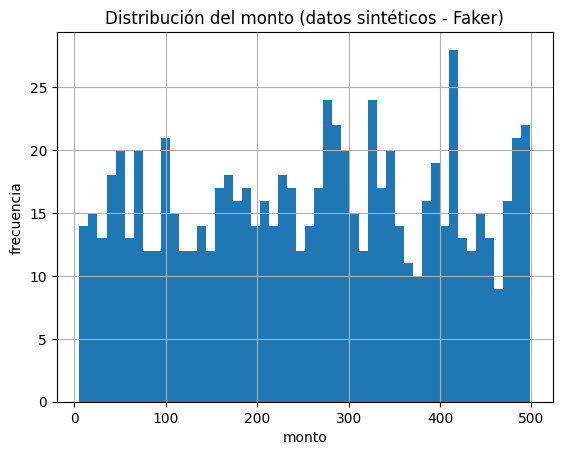

In [5]:

# Un vistazo gráfico simple (sin estilos ni seaborn)
plt.figure()
df['monto'].hist(bins=50)
plt.title('Distribución del monto (datos sintéticos - Faker)')
plt.xlabel('monto')
plt.ylabel('frecuencia')
plt.show()



## 4) Demo B — Generación con `SDV` (opcional, más "realista")
**Idea:** aprender de un dataset real y generar uno sintético con propiedades estadísticas similares.

A continuación usamos el dataset **Iris** como ejemplo por su simplicidad.


In [6]:
!pip install -q "sdv>=1.9,<2"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.6/215.6 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.9/259.9 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.3/90.3 kB 7.1 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.13/dist-packages/sdv/single_table/base.py:139: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


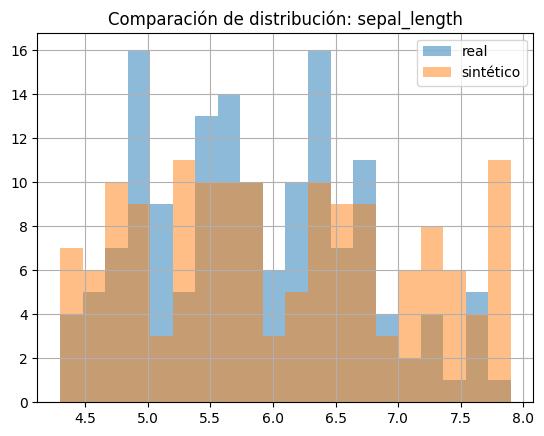

In [7]:
import pandas as pd
from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer
import matplotlib.pyplot as plt

# 1) Cargar dataset real
df_real = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv")


# 2) Detectar metadatos
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(df_real)


# 3) Entrenar sintetizador (CTGAN)
synth = CTGANSynthesizer(metadata)
synth.fit(df_real)

# 4) Generar datos sintéticos
df_synth = synth.sample(num_rows=len(df_real)) #mismo tamaño que el dataset real

# 5) Comparar distribuciones simples
plt.figure()
df_real['sepal_length'].hist(alpha=0.5, bins=20, label='real')
df_synth['sepal_length'].hist(alpha=0.5, bins=20, label='sintético')
plt.title('Comparación de distribución: sepal_length')
plt.legend()
plt.show()

In [10]:
df_real

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica



## 5) Comparación básica de distribuciones
Podemos contrastar estadísticas simples (media, desvío, cuartiles) y una métrica como **KS test** para una variable.

El KS statistic (o Kolmogorov–Smirnov test) es una prueba estadística no paramétrica usada para comparar dos distribuciones y ver si podrían provenir de la misma población.


In [8]:
from scipy.stats import ks_2samp
real = df_real['sepal_length'].dropna().values
synth_vals = df_synth['sepal_length'].dropna().values
stat, pvalue = ks_2samp(real, synth_vals)
print(f"KS statistic: {stat:.4f} | p-value: {pvalue:.4f}")



KS statistic: 0.1667 | p-value: 0.0308


## KS statistic
Representa la distancia máxima entre las dos distribuciones acumuladas (real vs. sintética).

Un valor de 0.1667 es relativamente bajo, lo que indica que las curvas se parecen bastante.

A modo de referencia:

D < 0.1 → casi idénticas.

0.1 ≤ D < 0.2 → diferencias leves.

D > 0.3 → distribuciones claramente distintas.

## p-value = 0.0308

Es mayor que el umbral común de 0.05 → no hay evidencia estadísticamente significativa de que las dos distribuciones sean diferentes.

En términos simples: no puedes rechazar la hipótesis nula de que provienen de la misma distribución.